# Banking Customer Churn Analysis

## Project Overview

This project analyzes customer churn patterns using exploratory data analysis, statistical testing, and machine learning.

The objective is to identify customer segments associated with higher churn rates and develop a baseline classification model to support data-driven customer retention strategies.

### Business Questions

1. Which customer characteristics are associated with higher churn rates?
2. Are there statistically significant associations between selected customer attributes and churn?
3. How well can a logistic regression model identify customers who are likely to churn?
4. How does changing the classification threshold affect churn detection?

## Dataset Description

This project uses a customer churn dataset containing 10,000 observations and 18 columns.

The dataset includes customer demographic information, account characteristics, banking product usage, and churn status.

### Target Variable

- **Exited:** Indicates whether a customer left the bank. A value of 1 represents a customer who exited, while 0 represents a customer who stayed.

### Key Variables

| Variable | Description |
|---|---|
| CreditScore | Customer's credit score |
| Geography | Customer's country or geographic market |
| Gender | Customer's gender category |
| Age | Customer's age |
| Tenure | Number of years the customer has been with the bank |
| Balance | Customer's account balance |
| NumOfProducts | Number of banking products held |
| HasCrCard | Indicates whether the customer has a credit card |
| IsActiveMember | Indicates whether the customer is an active member |
| EstimatedSalary | Customer's estimated salary |

The dataset also contains customer identifiers and additional variables that may require further assessment before predictive modeling.

In [2]:
import pandas as pd

df = pd.read_csv("Customer-Churn-Records.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [3]:
# Ukuran dataset: jumlah baris dan kolom
print("Dataset shape:", df.shape)

# Nama kolom dan tipe datanya
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

Dataset shape: (10000, 18)

Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain', 'Satisfaction Score', 'Card Type', 'Point Earned']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard 

In [4]:
# 1. Missing values
print("Total missing values:", df.isnull().sum().sum())

# 2. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 3. Duplicate customer IDs
print("Duplicate Customer IDs:", df["CustomerId"].duplicated().sum())

# 4. Distribusi target
print("\nExited distribution:")
display(df["Exited"].value_counts().rename(index={0: "Stayed", 1: "Exited"}))

print("\nExited percentage:")
display(
    (df["Exited"].value_counts(normalize=True) * 100)
    .rename(index={0: "Stayed", 1: "Exited"})
    .round(2)
)

Total missing values: 0
Duplicate rows: 0
Duplicate Customer IDs: 0

Exited distribution:


Exited
Stayed    7962
Exited    2038
Name: count, dtype: int64


Exited percentage:


Exited
Stayed    79.62
Exited    20.38
Name: proportion, dtype: float64

In [5]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5000.50,2886.90,1.00,2500.75,5000.50,7500.25,10000.00
CustomerId,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
CreditScore,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
NumOfProducts,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48


In [6]:
for col in ["Geography", "Gender", "NumOfProducts",
            "HasCrCard", "IsActiveMember", "Exited",
            "Complain", "Satisfaction Score", "Card Type"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Geography ---
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

--- Gender ---
Gender
Male      5457
Female    4543
Name: count, dtype: int64

--- NumOfProducts ---
NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

--- HasCrCard ---
HasCrCard
1    7055
0    2945
Name: count, dtype: int64

--- IsActiveMember ---
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

--- Exited ---
Exited
0    7962
1    2038
Name: count, dtype: int64

--- Complain ---
Complain
0    7956
1    2044
Name: count, dtype: int64

--- Satisfaction Score ---
Satisfaction Score
3    2042
2    2014
4    2008
5    2004
1    1932
Name: count, dtype: int64

--- Card Type ---
Card Type
DIAMOND     2507
GOLD        2502
SILVER      2496
PLATINUM    2495
Name: count, dtype: int64


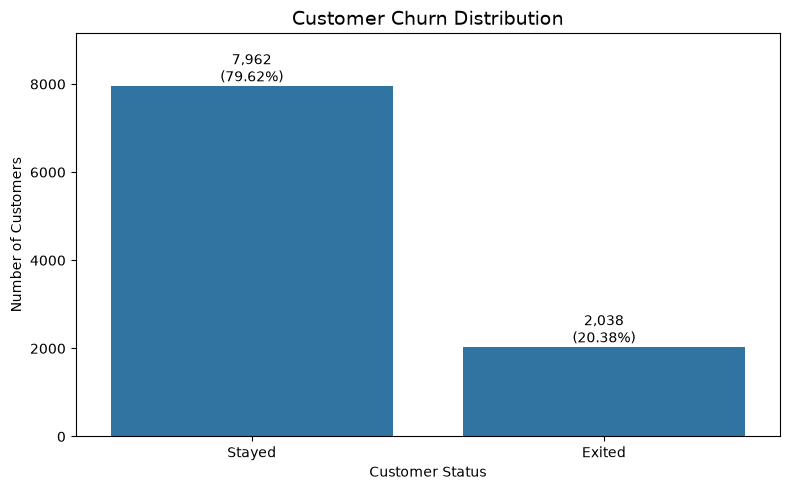

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hitung jumlah pelanggan berdasarkan status churn
churn_counts = df["Exited"].map({
    0: "Stayed",
    1: "Exited"
}).value_counts().reindex(["Stayed", "Exited"])

# Buat bar chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values
)

plt.title("Customer Churn Distribution", fontsize=14)
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

# Tambahkan label jumlah dan persentase
total = churn_counts.sum()

for i, value in enumerate(churn_counts.values):
    percentage = value / total * 100
    ax.text(
        i,
        value + 100,
        f"{value:,}\n({percentage:.2f}%)",
        ha="center"
    )

plt.ylim(0, churn_counts.max() * 1.15)
plt.tight_layout()
plt.show()

In [8]:
# Churn rate berdasarkan negara
geography_churn = (
    df.groupby("Geography")["Exited"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Churn Rate",
        "count": "Total Customers"
    })
)

geography_churn["Churn Rate"] *= 100

display(geography_churn.round(2))

,Churn Rate,Total Customers
Geography,,
France,16.17,5014
Germany,32.44,2509
Spain,16.67,2477


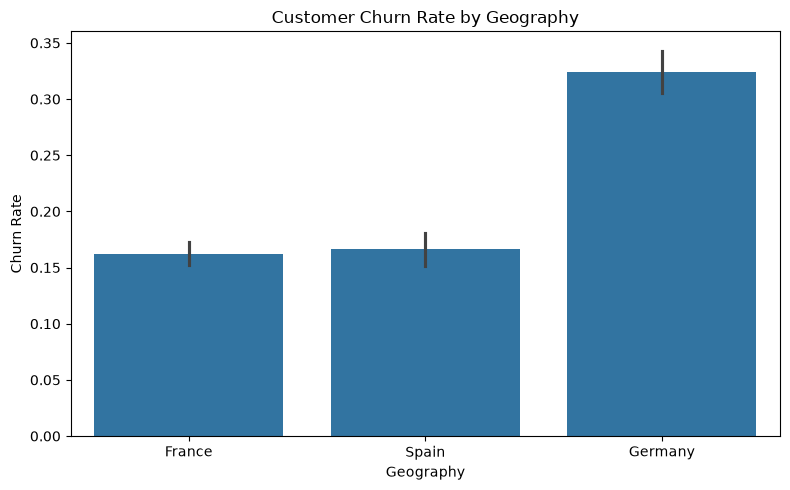

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Geography",
    y="Exited"
)

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()

In [10]:
# Kelompokkan usia pelanggan
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# Hitung jumlah pelanggan dan churn rate
age_churn = (
    df.groupby("AgeGroup", observed=True)["Exited"]
    .agg(["mean", "count", "sum"])
    .rename(columns={
        "mean": "ChurnRate",
        "count": "TotalCustomers",
        "sum": "ChurnedCustomers"
    })
)

age_churn["ChurnRate"] *= 100

display(age_churn.round(2))

,ChurnRate,TotalCustomers,ChurnedCustomers
AgeGroup,,,
18-25,7.53,611,46
26-35,8.50,3542,301
36-45,19.65,3736,734
46-55,50.57,1311,663
56+,36.75,800,294


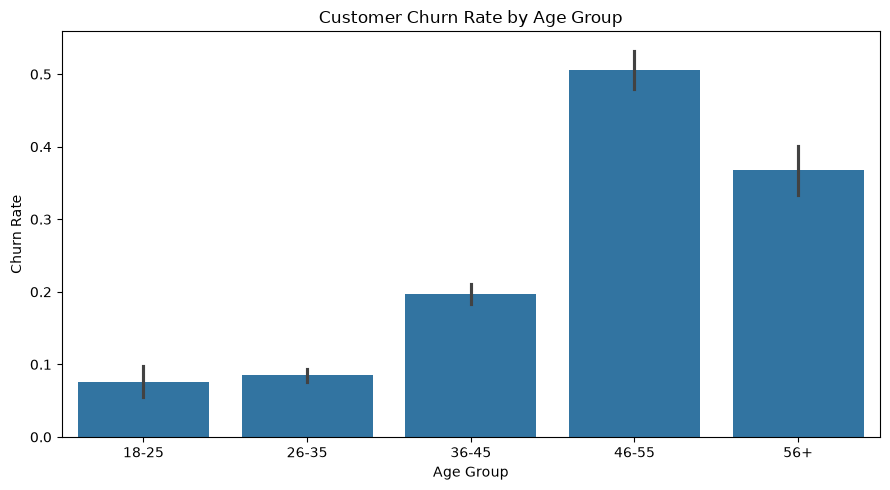

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="AgeGroup",
    y="Exited",
    order=["18-25", "26-35", "36-45", "46-55", "56+"]
)

plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()

In [12]:
activity_churn = (
    df.groupby("IsActiveMember")["Exited"]
    .agg(["mean", "count", "sum"])
    .rename(columns={
        "mean": "ChurnRate",
        "count": "TotalCustomers",
        "sum": "ChurnedCustomers"
    })
)

activity_churn["ChurnRate"] *= 100

activity_churn.index = activity_churn.index.map({
    0: "Inactive",
    1: "Active"
})

display(activity_churn.round(2))

,ChurnRate,TotalCustomers,ChurnedCustomers
IsActiveMember,,,
Inactive,26.87,4849,1303
Active,14.27,5151,735


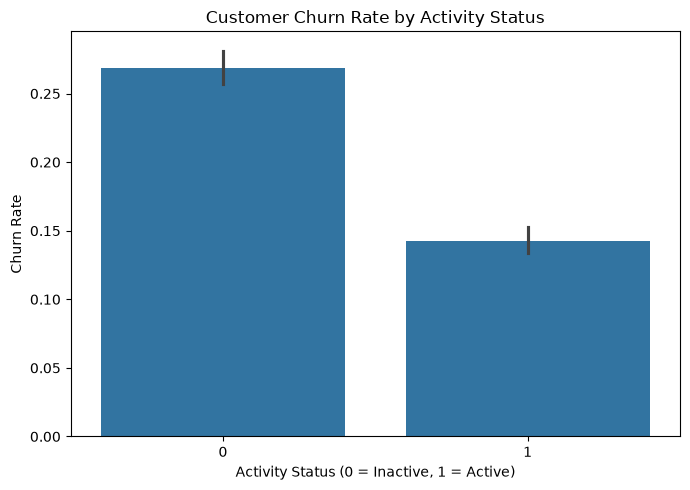

In [13]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="IsActiveMember",
    y="Exited"
)

plt.title("Customer Churn Rate by Activity Status")
plt.xlabel("Activity Status (0 = Inactive, 1 = Active)")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()

In [14]:
complain_churn = (
    df.groupby("Complain")["Exited"]
    .agg(["mean", "count", "sum"])
    .rename(columns={
        "mean": "ChurnRate",
        "count": "TotalCustomers",
        "sum": "ChurnedCustomers"
    })
)

complain_churn["ChurnRate"] *= 100

complain_churn.index = complain_churn.index.map({
    0: "No Complaint",
    1: "Complaint"
})

display(complain_churn.round(2))

,ChurnRate,TotalCustomers,ChurnedCustomers
Complain,,,
No Complaint,0.05,7956,4
Complaint,99.51,2044,2034


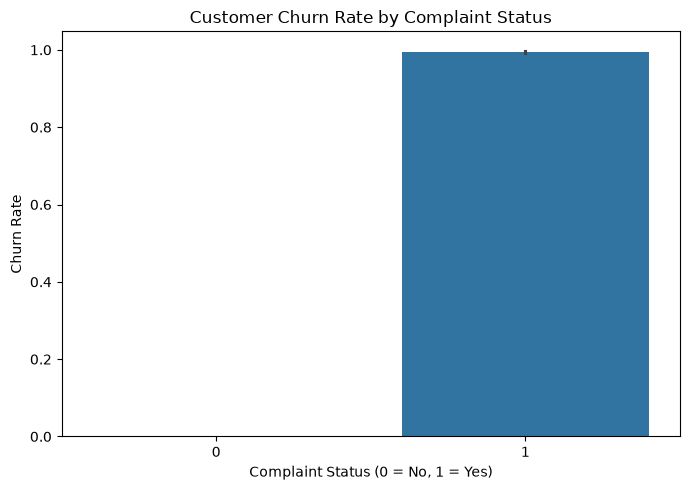

In [15]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Complain",
    y="Exited"
)

plt.title("Customer Churn Rate by Complaint Status")
plt.xlabel("Complaint Status (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()

In [16]:
satisfaction_churn = (
    df.groupby("Satisfaction Score")["Exited"]
    .agg(["mean", "count", "sum"])
    .rename(columns={
        "mean": "ChurnRate",
        "count": "TotalCustomers",
        "sum": "ChurnedCustomers"
    })
)

satisfaction_churn["ChurnRate"] *= 100

display(satisfaction_churn.round(2))

,ChurnRate,TotalCustomers,ChurnedCustomers
Satisfaction Score,,,
1,20.03,1932,387
2,21.80,2014,439
3,19.64,2042,401
4,20.62,2008,414
5,19.81,2004,397


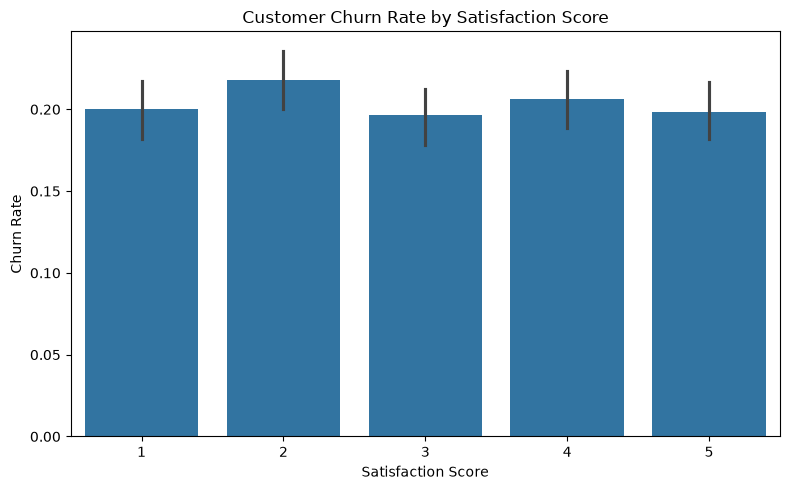

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Satisfaction Score",
    y="Exited"
)

plt.title("Customer Churn Rate by Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Churn Rate")
plt.tight_layout()
plt.show()

In [18]:
from scipy.stats import chi2_contingency

# Tabel silang
contingency_table = pd.crosstab(
    df["IsActiveMember"],
    df["Exited"]
)

display(contingency_table)

# Uji Chi-Square
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Conclusion: There is a statistically significant association.")
else:
    print("Conclusion: No statistically significant association was found.")

Exited,0,1
IsActiveMember,,
0,3546,1303
1,4416,735


Chi-square statistic: 243.6948
Degrees of freedom: 1
P-value: 6.153167438113408e-55
Conclusion: There is a statistically significant association.


In [19]:
activity_summary = (
    df.groupby("IsActiveMember", observed=True)["Exited"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "TotalCustomers",
        "sum": "ChurnedCustomers",
        "mean": "ChurnRate"
    })
)

activity_summary["ChurnRate"] *= 100

activity_summary.index = activity_summary.index.map({
    0: "Inactive",
    1: "Active"
})

display(activity_summary.round(2))

,TotalCustomers,ChurnedCustomers,ChurnRate
IsActiveMember,,,
Inactive,4849,1303,26.87
Active,5151,735,14.27


### Statistical Analysis: Customer Activity and Churn

- **Test:** Chi-Square Test of Independence
- **Significance level:** 0.05
- **P-value:** Less than 0.001
- **Conclusion:** There is a statistically significant association between customer activity status and churn status.
- **Business implication:** Inactive customers have a higher churn rate (26.87%) than active customers (14.27%). Customer activity may be useful for identifying customer segments that require further investigation.

**Note:** Statistical association does not imply causation.

In [20]:
from scipy.stats import chi2_contingency

categorical_vars = [
    "IsActiveMember",
    "Geography",
    "Gender",
    "Complain",
    "Satisfaction Score",
    "Card Type"
]

results = []

for col in categorical_vars:
    table = pd.crosstab(df[col], df["Exited"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    results.append({
        "Variable": col,
        "Chi2": chi2,
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Significant (0.05)": p_value < 0.05
    })

chi_square_results = pd.DataFrame(results)
display(chi_square_results.round(4))

,Variable,Chi2,Degrees of Freedom,P-value,Significant (0.05)
0,IsActiveMember,243.6948,1,0.0000,True
1,Geography,300.6264,2,0.0000,True
2,Gender,112.3966,1,0.0000,True
3,Complain,9907.9070,1,0.0000,True
4,Satisfaction Score,3.8027,4,0.4334,False
5,Card Type,5.0532,3,0.1679,False


In [21]:
from sklearn.model_selection import train_test_split

# Kolom yang tidak digunakan sebagai prediktor
exclude_cols = [
    "RowNumber",
    "CustomerId",
    "Surname",
    "Exited",
    "Complain",
    "Satisfaction Score",
    "AgeGroup"
]

X = df.drop(columns=exclude_cols, errors="ignore")
y = df["Exited"]

# Pisahkan data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training data: (8000, 12)
Testing data: (2000, 12)

Training churn rate: 20.38 %
Testing churn rate: 20.4 %


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identifikasi kolom berdasarkan tipe data
categorical_cols = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols)
    ]
)

# Pipeline model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Training
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Accuracy : 0.813
Precision: 0.6214
Recall   : 0.2132
F1-score : 0.3175
ROC-AUC  : 0.7783

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.97      0.89      1592
           1       0.62      0.21      0.32       408

    accuracy                           0.81      2000
   macro avg       0.72      0.59      0.60      2000
weighted avg       0.79      0.81      0.77      2000



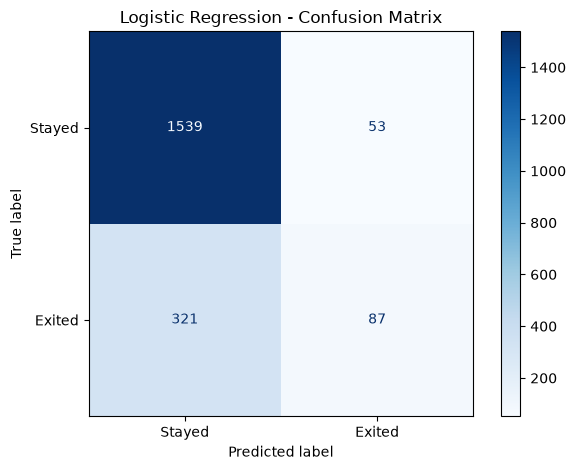

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Prediksi pada data testing
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Metrik evaluasi
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Exited"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Uji beberapa threshold probabilitas
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score
0,0.5,0.6214,0.2132,0.3175
1,0.4,0.5443,0.3162,0.4000
2,0.3,0.4875,0.5270,0.5065
3,0.2,0.3837,0.7402,0.5054
4,0.1,0.2637,0.9093,0.4088


In [25]:
from sklearn.metrics import confusion_matrix
import pandas as pd

comparison = []

for threshold in [0.3, 0.2]:
    pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    comparison.append({
        "Threshold": threshold,
        "True Positive (Churn terdeteksi)": tp,
        "False Negative (Churn terlewat)": fn,
        "False Positive (Salah ditandai churn)": fp,
        "True Negative (Stayed terdeteksi)": tn
    })

display(pd.DataFrame(comparison))

,Threshold,True Positive (Churn terdeteksi),False Negative (Churn terlewat),False Positive (Salah ditandai churn),True Negative (Stayed terdeteksi)
0,0.3,215,193,226,1366
1,0.2,302,106,485,1107


## Business Insights and Recommendations

### 1. Customer Activity

Inactive customers have a churn rate of 26.87%, compared with 14.27% among active customers.

**Recommendation:** Investigate customer engagement patterns and consider targeted retention campaigns for inactive customers.

### 2. Geographic Differences

Germany has the highest churn rate at 32.44%, compared with 16.17% in France and 16.67% in Spain.

**Recommendation:** Investigate potential differences in customer experience, product preferences, and service quality in Germany before designing market-specific retention strategies.

### 3. Age Group

Customers aged 46–55 have the highest churn rate at 50.57%, followed by customers aged 56 and above at 36.75%.

**Recommendation:** Examine the needs and experiences of customers aged 46–55 to identify potential retention opportunities.

### 4. Model Performance

The baseline Logistic Regression model achieved an accuracy of 81.30% and a ROC-AUC of 0.7783. At the default threshold of 0.5, recall for churn was only 21.32%.

Reducing the threshold to 0.3 increased recall to 52.70%, while a threshold of 0.2 increased recall to 74.02%.

**Recommendation:** Choose a classification threshold based on the trade-off between missed churn cases and unnecessary retention outreach. Validate the threshold using separate validation data before reporting final test performance.

**Important:** These findings represent associations and exploratory model results. They do not establish causation or guarantee business outcomes.

## Conclusion and Limitations

### Conclusion

This project explored customer churn patterns through exploratory data analysis, statistical testing, and a baseline Logistic Regression model.

The analysis identified several customer segments with higher churn rates:

- **Customer activity:** Inactive customers had a churn rate of 26.87%, compared with 14.27% among active customers.
- **Geography:** Germany had the highest churn rate at 32.44%, while France and Spain had churn rates of 16.17% and 16.67%, respectively.
- **Age group:** Customers aged 46–55 had the highest churn rate at 50.57%.

The baseline Logistic Regression model achieved an accuracy of 81.30% and a ROC-AUC of 0.7783. However, its recall for churn was only 21.32% at the default classification threshold of 0.5.

Lowering the threshold to 0.3 increased churn recall to 52.70%, with an F1-score of 0.5065. A threshold of 0.2 increased recall further to 74.02%, but also increased false positives. This illustrates the trade-off between identifying more customers at risk of churn and generating more unnecessary retention alerts.

### Limitations

- **Dataset scope:** The findings are based on the available dataset and may not represent all banking customers or real-world banking conditions.
- **Association, not causation:** Statistical associations do not establish that customer characteristics cause churn.
- **Baseline model:** Logistic Regression was used as an initial model. Its performance has not yet been comprehensively compared with alternative models.
- **Classification threshold:** Threshold comparisons are exploratory. Because the thresholds were evaluated on test-set predictions, an independent validation set should be used for threshold selection before final test evaluation.
- **Potential data leakage:** The timing and availability of predictor variables should be checked to ensure that they would be known before a customer churns.
- **Business recommendations:** Suggested retention strategies are hypotheses that require further investigation and evaluation.

### Future Work

Future analysis could compare Logistic Regression with other classification models, investigate feature importance, validate the classification threshold using separate validation data, and estimate the potential business impact of retention strategies.